### Import libraries and configure paths

In [1]:
from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

cwd = Path.cwd().resolve()

if (cwd / "data" / "processed").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "processed").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Processed data folder not found.")

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
MODEL_DIR = PROJECT_ROOT / "outputs" / "models"

for directory in [TABLE_DIR, FIGURE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)

Project root: E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research


### Load training, validation, and test datasets

In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

with open(
    DATA_DIR / "experiment_config.json",
    "r",
    encoding="utf-8"
) as file:
    config = json.load(file)

FEATURE_GROUPS = config["feature_groups"]

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nFeature groups:")
for name, columns in FEATURE_GROUPS.items():
    print(f"{name}: {len(columns)} features")

assert train_df["time_step"].max() < val_df["time_step"].min()
assert val_df["time_step"].max() < test_df["time_step"].min()

assert all(
    dataset["target"].nunique() == 2
    for dataset in [train_df, val_df, test_df]
)

Training: (29894, 175)
Validation: (7829, 175)
Testing: (8841, 175)

Feature groups:
Baseline: 165 features
Graph_Only: 7 features
Combined: 172 features


### Define target variables

In [3]:
y_train = train_df["target"].astype(int)
y_val = val_df["target"].astype(int)
y_test = test_df["target"].astype(int)

print("Training target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nIllicit class = 1")
print("Licit class = 0")

Training target distribution:
target
0    26432
1     3462
Name: count, dtype: int64

Validation target distribution:
target
0    7154
1     675
Name: count, dtype: int64

Test target distribution:
target
0    8433
1     408
Name: count, dtype: int64

Illicit class = 1
Licit class = 0


### Define model configuration

In [4]:
RF_PARAMS = {
    "n_estimators": 250,
    "max_depth": None,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "class_weight": "balanced_subsample",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

print("Random Forest configuration:")

for parameter, value in RF_PARAMS.items():
    print(f"{parameter}: {value}")

Random Forest configuration:
n_estimators: 250
max_depth: None
min_samples_split: 5
min_samples_leaf: 2
max_features: sqrt
class_weight: balanced_subsample
random_state: 42
n_jobs: -1


### Train the three Random Forest models

In [5]:
models = {}
validation_probabilities = {}
training_results = []

for name, columns in FEATURE_GROUPS.items():

    print(f"\nTraining {name} model...")

    X_train = train_df[columns]
    X_val = val_df[columns]

    model = RandomForestClassifier(**RF_PARAMS)

    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]

    models[name] = model
    validation_probabilities[name] = val_prob

    val_ap = average_precision_score(
        y_val, val_prob
    )

    val_roc_auc = roc_auc_score(
        y_val, val_prob
    )

    training_results.append({
        "Model": name,
        "Features": len(columns),
        "Validation_AP": val_ap,
        "Validation_ROC_AUC": val_roc_auc
    })

    print(f"Validation AP: {val_ap:.4f}")
    print(f"Validation ROC-AUC: {val_roc_auc:.4f}")

validation_results_df = pd.DataFrame(training_results)

display(validation_results_df)

validation_results_df.to_csv(
    TABLE_DIR / "12_validation_model_comparison.csv",
    index=False
)


Training Baseline model...
Validation AP: 0.9304
Validation ROC-AUC: 0.9782

Training Graph_Only model...
Validation AP: 0.1312
Validation ROC-AUC: 0.6059

Training Combined model...
Validation AP: 0.9325
Validation ROC-AUC: 0.9798


,Model,Features,Validation_AP,Validation_ROC_AUC
0,Baseline,165,0.930366,0.978197
1,Graph_Only,7,0.131157,0.605892
2,Combined,172,0.932461,0.979818


### Compare validation performance

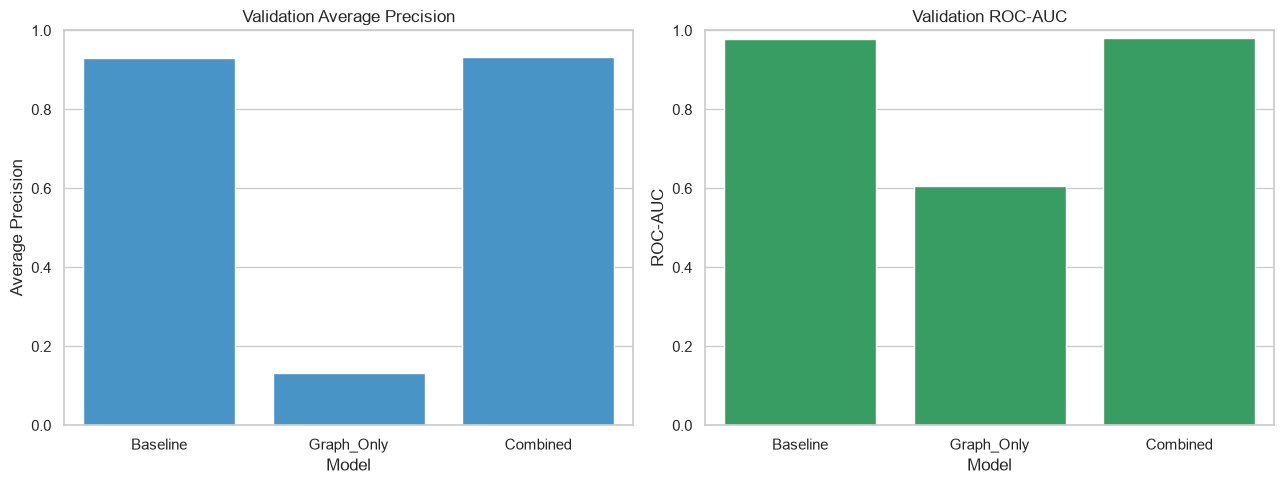

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=validation_results_df,
    x="Model",
    y="Validation_AP",
    ax=axes[0],
    color="#3498db"
)

axes[0].set_title("Validation Average Precision")
axes[0].set_ylabel("Average Precision")
axes[0].set_ylim(0, 1)

sns.barplot(
    data=validation_results_df,
    x="Model",
    y="Validation_ROC_AUC",
    ax=axes[1],
    color="#27ae60"
)

axes[1].set_title("Validation ROC-AUC")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "15_validation_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Select classification thresholds using validation data

In [7]:
def find_best_f1_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (
            precision[:-1]
            + recall[:-1]
            + 1e-12
        )
    )

    best_index = np.argmax(f1_values)

    return {
        "threshold": float(thresholds[best_index]),
        "precision": float(precision[best_index]),
        "recall": float(recall[best_index]),
        "f1": float(f1_values[best_index])
    }


threshold_results = {}

for name, probabilities in validation_probabilities.items():

    result = find_best_f1_threshold(
        y_val,
        probabilities
    )

    threshold_results[name] = result

threshold_df = pd.DataFrame([
    {
        "Model": name,
        "Selected_Threshold": result["threshold"],
        "Validation_Precision": result["precision"],
        "Validation_Recall": result["recall"],
        "Validation_F1": result["f1"]
    }
    for name, result in threshold_results.items()
])

display(threshold_df)

threshold_df.to_csv(
    TABLE_DIR / "13_selected_thresholds.csv",
    index=False
)

,Model,Selected_Threshold,Validation_Precision,Validation_Recall,Validation_F1
0,Baseline,0.533396,0.988176,0.866667,0.923441
1,Graph_Only,0.290052,0.126382,0.474074,0.199563
2,Combined,0.526580,0.989882,0.869630,0.925868


### Plot validation precision–recall curves

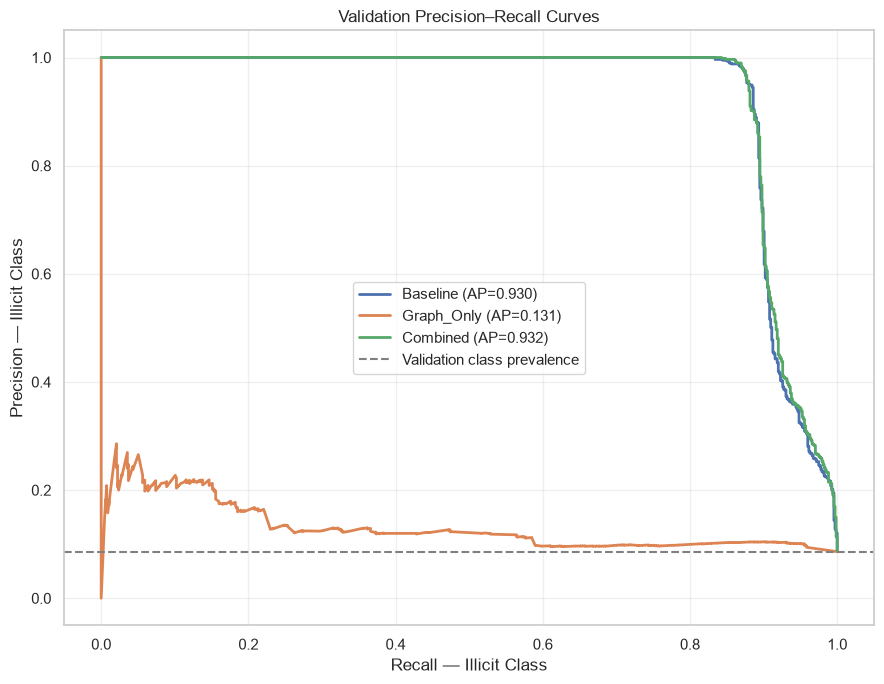

In [8]:
plt.figure(figsize=(9, 7))

for name, probabilities in validation_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    ap = average_precision_score(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})",
        linewidth=2
    )

plt.axhline(
    y=y_val.mean(),
    color="gray",
    linestyle="--",
    label="Validation class prevalence"
)

plt.title("Validation Precision–Recall Curves")
plt.xlabel("Recall — Illicit Class")
plt.ylabel("Precision — Illicit Class")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "16_validation_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Evaluate all models on the test set

In [9]:
test_probabilities = {}
test_predictions = []
test_results = []

for name, columns in FEATURE_GROUPS.items():

    model = models[name]

    X_test = test_df[columns]

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    threshold = threshold_results[name]["threshold"]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    test_probabilities[name] = probabilities

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    test_results.append({
        "Model": name,
        "Features": len(columns),
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "AP": average_precision_score(
            y_test, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            y_test, probabilities
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    test_predictions.append(
        pd.DataFrame({
            "txId": test_df["txId"],
            "time_step": test_df["time_step"],
            "target": y_test,
            "Model": name,
            "Probability": probabilities,
            "Prediction": predictions
        })
    )

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

test_results_df.to_csv(
    TABLE_DIR / "14_test_model_comparison.csv",
    index=False
)

all_predictions_df = pd.concat(
    test_predictions,
    ignore_index=True
)

all_predictions_df.to_csv(
    TABLE_DIR / "15_test_predictions.csv",
    index=False
)

,Model,Features,Threshold,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP
0,Baseline,165,0.5334,0.9738,0.9272,0.4681,0.6221,0.5479,0.8569,8418,15,217,191
1,Graph_Only,7,0.2901,0.5404,0.0342,0.3284,0.0619,0.0369,0.3676,4644,3789,274,134
2,Combined,172,0.5266,0.9738,0.9272,0.4681,0.6221,0.5470,0.8522,8418,15,217,191


### Print classification reports

In [10]:
for name in FEATURE_GROUPS:

    probabilities = test_probabilities[name]

    threshold = threshold_results[name]["threshold"]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Licit", "Illicit"],
            zero_division=0
        )
    )


BASELINE
              precision    recall  f1-score   support

       Licit       0.97      1.00      0.99      8433
     Illicit       0.93      0.47      0.62       408

    accuracy                           0.97      8841
   macro avg       0.95      0.73      0.80      8841
weighted avg       0.97      0.97      0.97      8841


GRAPH_ONLY
              precision    recall  f1-score   support

       Licit       0.94      0.55      0.70      8433
     Illicit       0.03      0.33      0.06       408

    accuracy                           0.54      8841
   macro avg       0.49      0.44      0.38      8841
weighted avg       0.90      0.54      0.67      8841


COMBINED
              precision    recall  f1-score   support

       Licit       0.97      1.00      0.99      8433
     Illicit       0.93      0.47      0.62       408

    accuracy                           0.97      8841
   macro avg       0.95      0.73      0.80      8841
weighted avg       0.97      0.97      0.9

### Plot test confusion matrices

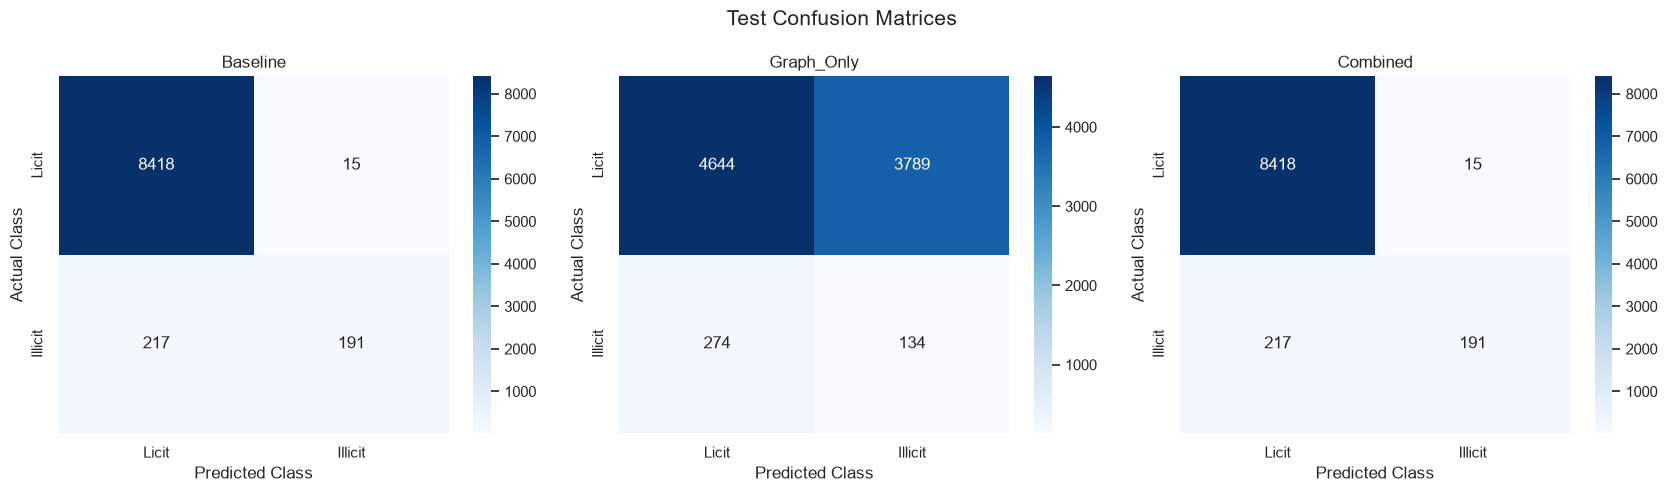

In [11]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, name in zip(axes, FEATURE_GROUPS):

    probabilities = test_probabilities[name]
    threshold = threshold_results[name]["threshold"]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Licit", "Illicit"],
        yticklabels=["Licit", "Illicit"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Test Confusion Matrices",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "17_test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Compare test precision, recall, and F1

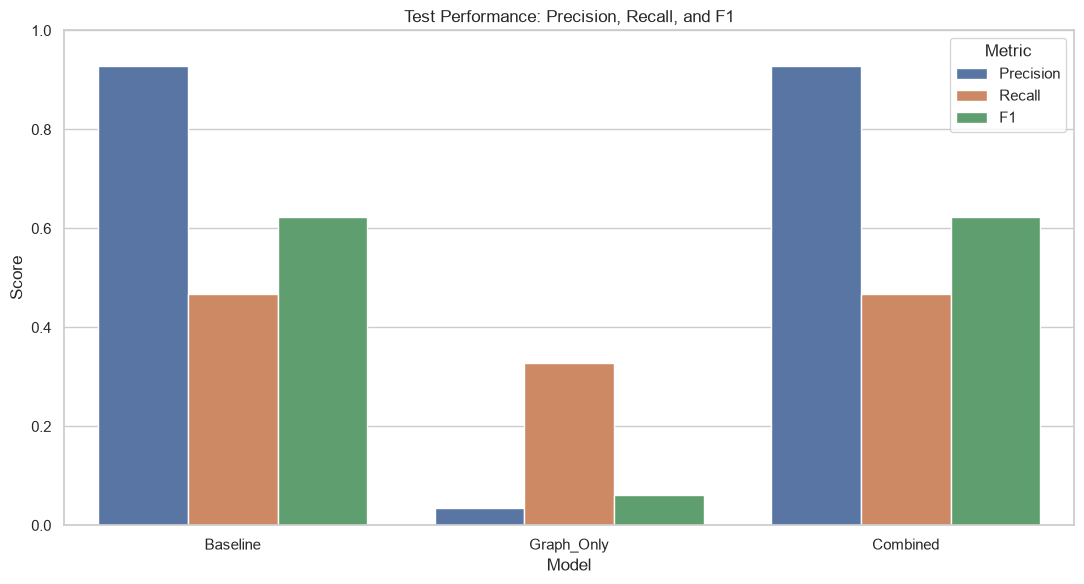

In [12]:
metrics_plot = test_results_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=metrics_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Test Performance: Precision, Recall, and F1")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "18_test_classification_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Plot test precision–recall curves

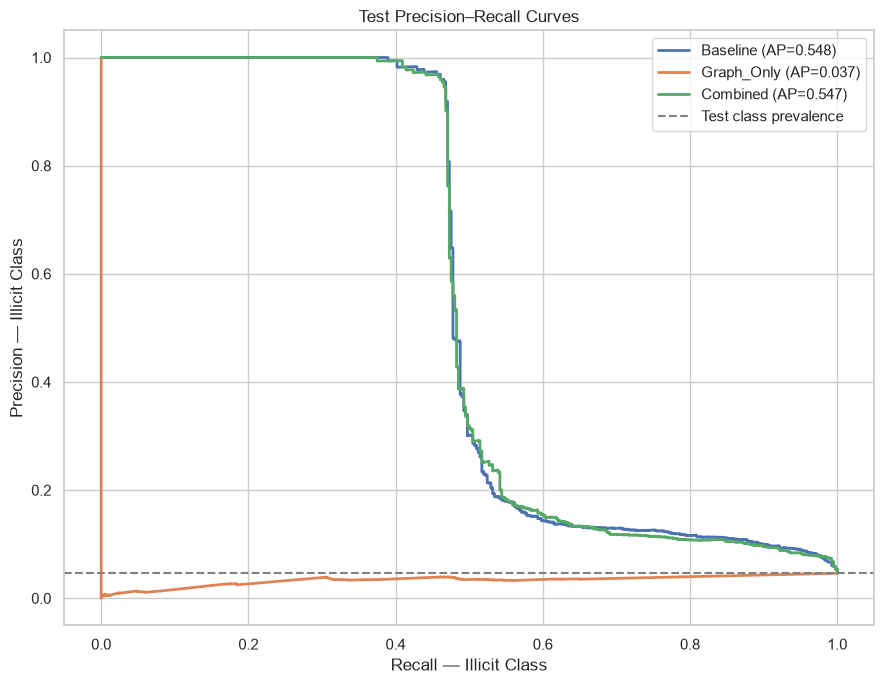

In [13]:
plt.figure(figsize=(9, 7))

for name, probabilities in test_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP={ap:.3f})"
    )

plt.axhline(
    y=y_test.mean(),
    color="gray",
    linestyle="--",
    label="Test class prevalence"
)

plt.title("Test Precision–Recall Curves")
plt.xlabel("Recall — Illicit Class")
plt.ylabel("Precision — Illicit Class")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "19_test_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Plot test ROC curves

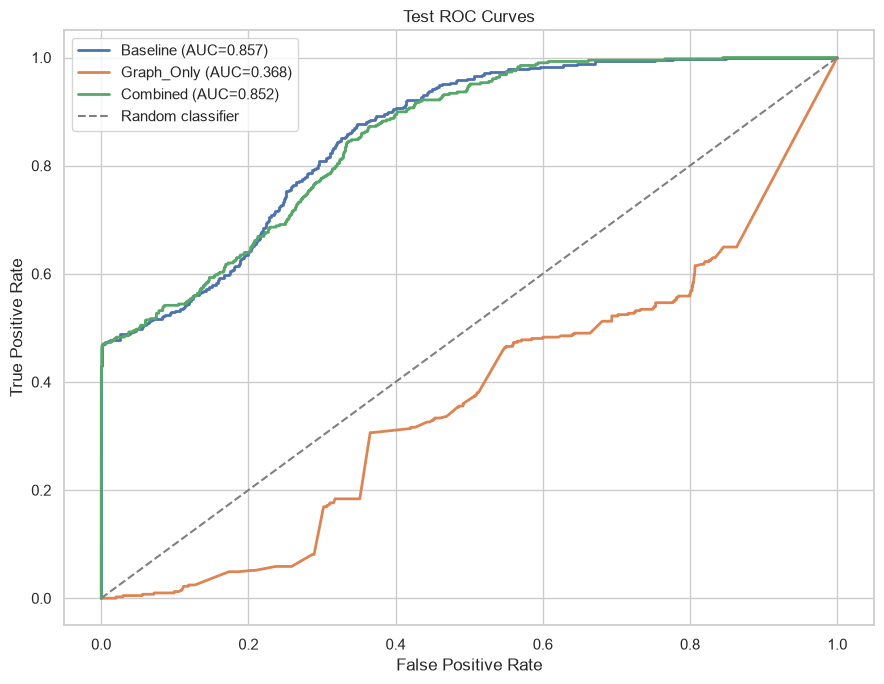

In [14]:
plt.figure(figsize=(9, 7))

for name, probabilities in test_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.title("Test ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "20_test_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Calculate the incremental value of graph features

Our central research question is whether combining graph-theoretical features with original transaction features improves detection.

We calculate the difference between the Combined model and Baseline model.

$$\Delta M = M_{\text{Combined}} - M_{\text{Baseline}}$$

In [15]:
baseline = test_results_df.set_index("Model").loc["Baseline"]
combined = test_results_df.set_index("Model").loc["Combined"]

comparison_metrics = [
    "Precision",
    "Recall",
    "F1",
    "AP",
    "ROC_AUC"
]

improvement_results = pd.DataFrame([
    {
        "Metric": metric,
        "Baseline": baseline[metric],
        "Combined": combined[metric],
        "Absolute_Change": (
            combined[metric] - baseline[metric]
        )
    }
    for metric in comparison_metrics
])

display(improvement_results.round(4))

improvement_results.to_csv(
    TABLE_DIR / "16_graph_feature_improvement.csv",
    index=False
)

print("\nCombined vs Baseline:")

for _, row in improvement_results.iterrows():

    change = row["Absolute_Change"]

    print(
        f"{row['Metric']}: "
        f"{change:+.4f}"
    )

,Metric,Baseline,Combined,Absolute_Change
0,Precision,0.9272,0.9272,0.0000
1,Recall,0.4681,0.4681,0.0000
2,F1,0.6221,0.6221,0.0000
3,AP,0.5479,0.5470,-0.0009
4,ROC_AUC,0.8569,0.8522,-0.0048



Combined vs Baseline:
Precision: +0.0000
Recall: +0.0000
F1: +0.0000
AP: -0.0009
ROC_AUC: -0.0048


### Analyze feature importance

In [16]:
importance_results = {}

for name, model in models.items():

    columns = FEATURE_GROUPS[name]

    importance_df = pd.DataFrame({
        "Feature": columns,
        "Importance": model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    importance_results[name] = importance_df

    importance_df.to_csv(
        TABLE_DIR / f"17_feature_importance_{name}.csv",
        index=False
    )

    print(f"\nTop 10 features: {name}")

    display(importance_df.head(10))


Top 10 features: Baseline


,Feature,Importance
54,feature_55,0.052786
52,feature_53,0.048212
46,feature_47,0.044557
48,feature_49,0.043172
40,feature_41,0.038814
42,feature_43,0.036016
17,feature_18,0.030159
4,feature_5,0.025567
89,feature_90,0.022941
131,feature_132,0.022845



Top 10 features: Graph_Only


,Feature,Importance
5,component_size,0.387128
6,pagerank_scaled,0.366990
0,in_degree,0.063546
2,total_degree,0.062717
1,out_degree,0.042039
3,degree_difference,0.038858
4,degree_ratio,0.038722



Top 10 features: Combined


,Feature,Importance
52,feature_53,0.058798
46,feature_47,0.056221
40,feature_41,0.050435
54,feature_55,0.048549
89,feature_90,0.041314
42,feature_43,0.033411
48,feature_49,0.030691
1,feature_2,0.023810
4,feature_5,0.022531
53,feature_54,0.021853


### Visualize the most important graph features

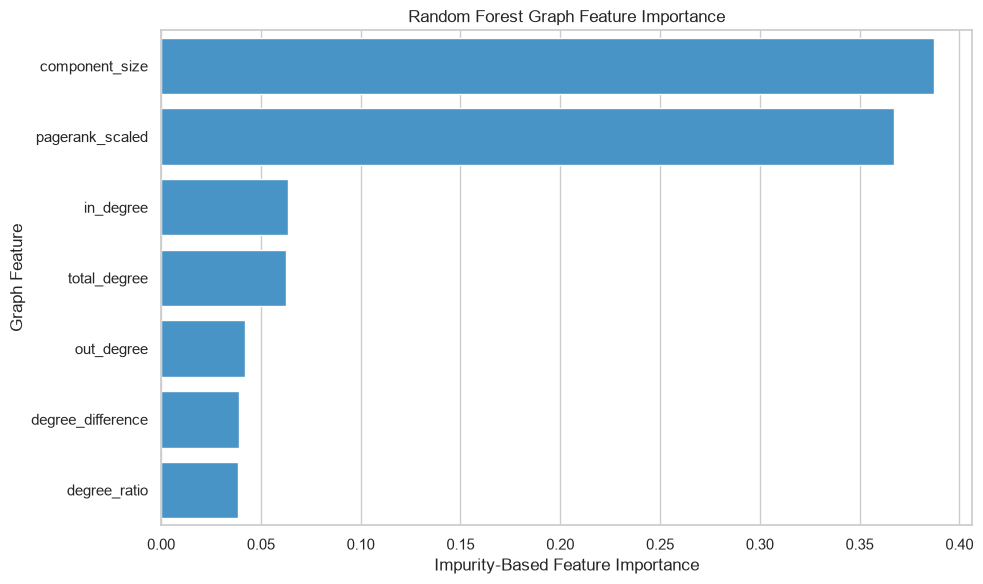

In [17]:
graph_importance = importance_results["Graph_Only"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=graph_importance,
    x="Importance",
    y="Feature",
    color="#3498db"
)

plt.title("Random Forest Graph Feature Importance")
plt.xlabel("Impurity-Based Feature Importance")
plt.ylabel("Graph Feature")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "21_graph_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Visualize top features in the Combined model

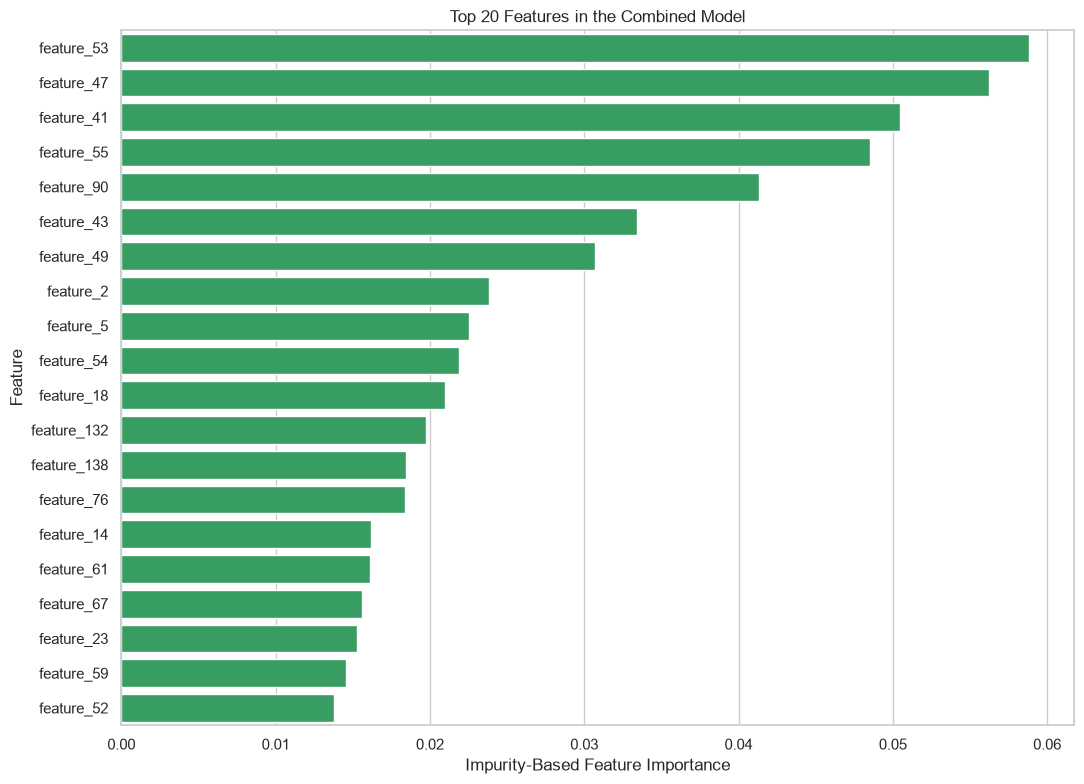

In [18]:
combined_importance = (
    importance_results["Combined"].head(20)
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=combined_importance,
    x="Importance",
    y="Feature",
    color="#27ae60"
)

plt.title("Top 20 Features in the Combined Model")
plt.xlabel("Impurity-Based Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "22_combined_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Save trained models and thresholds

In [19]:
for name, model in models.items():

    model_path = MODEL_DIR / f"random_forest_{name}.joblib"

    joblib.dump(model, model_path)

    print("Saved:", model_path.name)

threshold_export = {
    name: result["threshold"]
    for name, result in threshold_results.items()
}

with open(
    MODEL_DIR / "selected_thresholds.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        threshold_export,
        file,
        indent=4
    )

print("\nAll models and thresholds saved.")

Saved: random_forest_Baseline.joblib
Saved: random_forest_Graph_Only.joblib
Saved: random_forest_Combined.joblib

All models and thresholds saved.


### Identify the best validation model

In [20]:
best_validation_row = (
    validation_results_df.sort_values(
        "Validation_AP",
        ascending=False
    ).iloc[0]
)

best_model_name = best_validation_row["Model"]

print("BEST MODEL BY VALIDATION AP")
print("=" * 50)

print("Model:", best_model_name)
print(
    "Validation AP:",
    round(best_validation_row["Validation_AP"], 4)
)

best_test_row = (
    test_results_df.set_index("Model")
    .loc[best_model_name]
)

print("\nSelected model's test performance:")

for metric in [
    "Precision",
    "Recall",
    "F1",
    "AP",
    "ROC_AUC"
]:
    print(
        f"{metric}: {best_test_row[metric]:.4f}"
    )

BEST MODEL BY VALIDATION AP
Model: Combined
Validation AP: 0.9325

Selected model's test performance:
Precision: 0.9272
Recall: 0.4681
F1: 0.6221
AP: 0.5470
ROC_AUC: 0.8522


### Final notebook validation

In [21]:
print("=" * 60)
print("NOTEBOOK 04 - FINAL VALIDATION")
print("=" * 60)

checks = {
    "Three models trained": len(models) == 3,
    "Three validation results": len(validation_results_df) == 3,
    "Three test results": len(test_results_df) == 3,
    "All thresholds selected": len(threshold_results) == 3,
    "All models saved": all(
        (
            MODEL_DIR / f"random_forest_{name}.joblib"
        ).exists()
        for name in FEATURE_GROUPS
    ),
    "All test predictions saved": (
        TABLE_DIR / "15_test_predictions.csv"
    ).exists(),
    "All evaluation metrics finite": np.isfinite(
        test_results_df[
            [
                "Accuracy",
                "Precision",
                "Recall",
                "F1",
                "AP",
                "ROC_AUC"
            ]
        ].to_numpy(dtype=float)
    ).all(),
    "Test confusion matrix totals correct": all(
        (
            row["TN"]
            + row["FP"]
            + row["FN"]
            + row["TP"]
        ) == len(test_df)
        for _, row in test_results_df.iterrows()
    )
}

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'CHECK'}: {name}"
    )

if all(checks.values()):
    print("\nNotebook 04 completed successfully!")
else:
    print("\nReview flagged checks.")

NOTEBOOK 04 - FINAL VALIDATION
PASS: Three models trained
PASS: Three validation results
PASS: Three test results
PASS: All thresholds selected
PASS: All models saved
PASS: All test predictions saved
PASS: All evaluation metrics finite
PASS: Test confusion matrix totals correct

Notebook 04 completed successfully!
